# M08 — More Complex Models & Performance Evaluation
**QM 47400 · Group 22-002** — Jeffrey Wan, Nitya Jhaveri, Christopher Weng, Kyle Cuson

This notebook produces every number and figure in `22_complex_models.pdf`: **Section 0** (prediction goal),
**1a** (baseline: LASSO logistic regression with feature selection inside 5-fold CV, replicated from M06) and
**1b** (random forest and gradient boosting, tuned with `GridSearchCV` on the same folds, then compared with the
baseline using paired per-fold differences against the **0.02 PR-AUC margin declared in M06**).

**Course rules followed**
* **Test set stays locked (nb08/nb14).** The data are split by fiscal year: train = 1999–2013, validation = 2014–2016,
  test = 2017–2018. All tuning and every comparison use cross-validation inside 1999–2013 only.
* **All preprocessing inside one `Pipeline` (nb02/nb09).** Feature building, winsorizing, imputation and scaling are
  refit on each training fold, for every model, so the baseline and the complex models see identical inputs.
* **Identical folds for every candidate (nb14).** The same 5 time-ordered folds score the baseline, both grids and the
  final comparison, so per-fold differences are paired.

**Data.** Put the Kaggle file (Lombardo et al., 2022, *American Companies Bankruptcy Prediction Dataset*) at
`data/american_bankruptcy.csv` (or one folder up). **Run time:** about 10 minutes on a 10-core laptop (the two grids
are most of it); expect 30–40 minutes on a 2-core Colab runtime.

### 📝 How to use this notebook (for whoever writes `22_complex_models.pdf`)
* Cells headed **📝 Notes for the report** explain the output directly above them: what it shows, why it matters, and
  sentences you can adapt. Every number quoted in a note comes from this notebook's run on the real data.
* **Figures** are saved in `figures/` (white background, 250 dpi). Suggested placement:

| Figure file | Report section | Shows |
|---|---|---|
| `m08_fig1_lasso_path.png` | 1a. Baseline | LASSO penalty vs CV PR-AUC and number of ratios kept |
| `m08_fig2_rf_grid.png` | 1b. Tuning | random forest grid: CV PR-AUC for every combination |
| `m08_fig3_gb_grid.png` | 1b. Tuning | gradient boosting grid: CV PR-AUC for every combination |
| `m08_fig4_comparison.png` | 1b. Final comparison | PR-AUC by validation year; paired differences vs the margin |
| `m08_fig5_champion.png` | 1b. Interpretation | precision–recall curves; what drives the tuned model's predictions |

* **Key code snippets for the PDF:** the `make_model_pipe` cell (§1b.1), the two `GridSearchCV` cells (§1b.3–1b.4)
  and the `paired_rule` cell (§1b.5).

## Setup

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

RANDOM_SEED = 474
DATA_PATH = next((p for p in ["data/american_bankruptcy.csv", "../data/american_bankruptcy.csv",
                              "../american_bankruptcy.csv"] if os.path.exists(p)),
                 "data/american_bankruptcy.csv")   # works from M08/, the repo root, or with a data/ folder
TRAIN_END, VAL_END = 2013, 2016            # test = 2017–2018 (locked)
MARGIN = 0.02                              # PR-AUC gain a complex model must clear; declared in M06 §4c, before M08
os.makedirs("figures", exist_ok=True)
# NumPy on macOS (Accelerate BLAS) emits spurious "encountered in matmul" warnings during logistic fits; results are finite
warnings.filterwarnings("ignore", message=".*encountered in matmul")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)

# Figures: opaque white background, dark high-contrast text (same style as M06)
C_BASE, C_RF, C_GB, C_ALT = "#1f5fbf", "#1a8a5a", "#e07b00", "#d1495b"
INK, GRID = "#111111", "#dddddd"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "savefig.transparent": False, "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": INK,
    "xtick.color": INK, "ytick.color": INK, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "legend.frameon": False,
    "figure.dpi": 110,
})
print("scikit-learn", sklearn.__version__, "| data:", DATA_PATH)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


scikit-learn 1.6.1 | data: ../american_bankruptcy.csv


## Data, target, features and folds (unchanged from M06)
Condensed from M06 §1.1–2.3, with no changes: the one-year-ahead target (y = 1 only on a failed firm's last annual
report), the prior-year columns for the momentum features, the chronological split made before anything else, the
17 engineered ratios and the 5 time-ordered, expanding-window folds (validate on 2009, …, 2013, each fold training only
on earlier years). The industry `Division` merge from M06 is left out because no model in M06 or M08 uses it.

In [2]:
NAMES = {"X1": "current_assets", "X2": "cogs", "X3": "dep_amort", "X4": "ebitda", "X5": "inventory",
         "X6": "net_income", "X7": "receivables", "X8": "market_value", "X9": "net_sales",
         "X10": "total_assets", "X11": "lt_debt", "X12": "ebit", "X13": "gross_profit",
         "X14": "current_liab", "X15": "retained_earn", "X16": "total_revenue",
         "X17": "total_liab", "X18": "total_opex"}
df = pd.read_csv(DATA_PATH).rename(columns=NAMES)
RAW = list(NAMES.values())

# Target: y = 1 only on a failed firm's last annual report (M06 §1.2)
df = df.sort_values(["company_name", "year"]).reset_index(drop=True)
df["raw_failed"] = (df.status_label == "failed").astype(int)
last_year = df.groupby("company_name").year.transform("max")
df["y"] = ((df.raw_failed == 1) & (df.year == last_year)).astype(int)

# Prior-year raw figures, only when the prior report is exactly year t−1 (M06 §1.3)
LAG_SRC = ["total_liab", "total_assets", "net_income", "total_revenue", "market_value"]
prev = df.groupby("company_name")[LAG_SRC + ["year"]].shift(1)
adjacent = (df.year - prev.year) == 1
for c in LAG_SRC:
    df[f"prev_{c}"] = prev[c].where(adjacent)

RAW_KEEP = [c for c in RAW if c != "net_sales"]          # net_sales duplicates total_revenue
INPUT_COLS = RAW_KEEP + [f"prev_{c}" for c in LAG_SRC]

df["split"] = np.select([df.year <= TRAIN_END, df.year <= VAL_END], ["train", "validation"], "test")
train = df[df.split == "train"].copy()
Xtr, ytr = train[INPUT_COLS], train.y.values
print(f"Training years 1999–{TRAIN_END}: {len(train):,} firm-years, {int(ytr.sum())} failures ({ytr.mean():.2%}); "
      f"validation and test years stay locked ({(df.split != 'train').sum():,} rows)")

Training years 1999–2013: 62,896 firm-years, 457 failures (0.73%); validation and test years stay locked (15,786 rows)


In [3]:
def _div(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(np.abs(b) > 1e-9, a / b, np.nan)

def build_features(X):
    # Stateless row-wise arithmetic on raw + prior-year columns (learns nothing → safe inside the Pipeline)
    F = pd.DataFrame(index=X.index)
    # Altman's five ratios
    F["Working capital / assets"]   = _div(X.current_assets - X.current_liab, X.total_assets)
    F["Retained earnings / assets"] = _div(X.retained_earn, X.total_assets)
    F["EBIT / assets"]              = _div(X.ebit, X.total_assets)
    F["Market value / liabilities"] = _div(X.market_value, X.total_liab)
    F["Sales / assets"]             = _div(X.total_revenue, X.total_assets)
    # Leverage and liquidity
    F["Liabilities / assets"]       = _div(X.total_liab, X.total_assets)
    F["Long-term debt / assets"]    = _div(X.lt_debt, X.total_assets)
    F["Current ratio"]              = _div(X.current_assets, X.current_liab)
    # Profitability
    F["Net income / assets"]        = _div(X.net_income, X.total_assets)
    F["Gross margin"]               = _div(X.gross_profit, X.total_revenue)
    F["EBITDA / liabilities"]       = _div(X.ebitda, X.total_liab)
    # Size
    F["Log total assets"]           = np.log1p(X.total_assets.clip(lower=0))
    F["Log market value"]           = np.log1p(X.market_value.clip(lower=0))
    # Momentum: change since the prior year's report (missing when there is no t−1 report)
    F["Change in liabilities / assets"] = F["Liabilities / assets"] - _div(X.prev_total_liab, X.prev_total_assets)
    F["Change in net income / assets"]  = F["Net income / assets"] - _div(X.prev_net_income, X.prev_total_assets)
    F["Sales growth"]        = _div(X.total_revenue - X.prev_total_revenue, np.abs(X.prev_total_revenue))
    F["Market value growth"] = _div(X.market_value - X.prev_market_value, np.abs(X.prev_market_value))
    F = F.replace([np.inf, -np.inf], np.nan)
    if "Division" in X:
        F["Division"] = X["Division"].fillna("Unknown").astype(str)
    return F

def altman_z(F):
    return (1.2 * F["Working capital / assets"] + 1.4 * F["Retained earnings / assets"] + 3.3 * F["EBIT / assets"]
            + 0.6 * F["Market value / liabilities"] + 1.0 * F["Sales / assets"])

NUM_FEATS = list(build_features(Xtr.head()).columns)     # the 17 engineered ratios
MOMENTUM = NUM_FEATS[13:]

In [4]:
class Winsorizer(BaseEstimator, TransformerMixin):
    # Clip each column to [lower, upper] quantiles learned in fit (training fold only)
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_, self.hi_ = X.quantile(self.lower).values, X.quantile(self.upper).values
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

def numeric_pre(cols):
    return ColumnTransformer([("num", Pipeline([("clip", Winsorizer()),
                                                 ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                                                 ("scale", StandardScaler())]), cols)])

years = train.year.values
folds = [(np.where(years < v)[0], np.where(years == v)[0]) for v in range(TRAIN_END - 4, TRAIN_END + 1)]
FOLD_YEARS = list(range(TRAIN_END - 4, TRAIN_END + 1))
pd.DataFrame([{"validate on": v, "train years": f"1999–{v - 1}", "train rows": len(tr), "val rows": len(va),
               "val failures": int(ytr[va].sum())} for v, (tr, va) in zip(FOLD_YEARS, folds)]).set_index("validate on")

,train years,train rows,val rows,val failures
validate on,,,,
2009,1999–2008,45046,3743,23
2010,1999–2009,48789,3625,35
2011,1999–2010,52414,3513,25
2012,1999–2011,55927,3485,26
2013,1999–2012,59412,3484,28


In [5]:
# Shared evaluation helpers: every model is scored by the same function on the same folds
def recall_at_top(y, s, frac=0.05):
    y, s = np.asarray(y), np.asarray(s)
    k = max(1, int(np.ceil(frac * len(s))))
    return y[np.argsort(-s)[:k]].sum() / max(1, y.sum())

def t_half(x):
    # 95% Student's t half-width over k folds (nb08)
    x = np.asarray(x, float); k = len(x)
    return stats.t.ppf(0.975, df=k - 1) * x.std(ddof=1) / np.sqrt(k)

def fold_metrics(pipe):
    ap, roc, rec, fit_s = [], [], [], []
    oof = np.full(len(ytr), np.nan)
    for tr, va in folds:
        t0 = time.time()
        pipe.fit(Xtr.iloc[tr], ytr[tr])
        fit_s.append(time.time() - t0)
        p = pipe.predict_proba(Xtr.iloc[va])[:, 1]
        oof[va] = p
        ap.append(average_precision_score(ytr[va], p)); roc.append(roc_auc_score(ytr[va], p))
        rec.append(recall_at_top(ytr[va], p))
    return dict(ap=np.array(ap), roc=np.array(roc), rec=np.array(rec), oof=oof, fit_s=float(np.mean(fit_s)))

# Altman Z (fixed 1968 formula, nothing fitted) and no-skill, the reference floors from M06
F_all = build_features(Xtr)
z = -(1.2 * F_all["Working capital / assets"] + 1.4 * F_all["Retained earnings / assets"] + 3.3 * F_all["EBIT / assets"]
      + 0.6 * F_all["Market value / liabilities"] + 1.0 * F_all["Sales / assets"])
z = z.fillna(z.median()).values
altman = dict(ap=np.array([average_precision_score(ytr[va], z[va]) for _, va in folds]),
              roc=np.array([roc_auc_score(ytr[va], z[va]) for _, va in folds]),
              rec=np.array([recall_at_top(ytr[va], z[va]) for _, va in folds]),
              oof=np.where(np.isin(np.arange(len(ytr)), np.concatenate([va for _, va in folds])), z, np.nan), fit_s=0.0)
no_skill = np.array([ytr[va].mean() for _, va in folds])
print(f"Altman Z CV PR-AUC {altman['ap'].mean():.4f} | no-skill {no_skill.mean():.4f}")

Altman Z CV PR-AUC 0.0225 | no-skill 0.0077


## Section 0 — Prediction goal
**Goal.** For a U.S. public company, use the financial statements in its most recent annual report (fiscal year *t*)
to predict the **probability that it files for Chapter 7 or Chapter 11 bankruptcy within the next year**, then rank
firms by that probability and identify which financial ratios drive the risk.

**Type of problem.** The response is binary (files within a year: yes/no), so this is **classification**, not
regression. Models output a probability, and we judge how well they rank failures above survivors.

**Metric.** **PR-AUC** (average precision) is the selection metric, as in M06. Only 0.73% of training firm-years are
failures, so accuracy is useless (predicting "nobody fails" scores 99.3%) and ROC-AUC looks flattering. PR-AUC measures
how clean the top of the risk list is, which is what an analyst reviewing a watch list needs; its no-skill value equals
the prevalence (≈ 0.008 in the validation years). We also report ROC-AUC and **recall in the riskiest 5%** (share of
next-year bankruptcies caught if analysts review the top 5% of firms).

**Why it matters.** Lenders, suppliers and investors lose money on every bankruptcy they miss. The industry-standard
screen, the 1968 Altman Z-score, puts 36% of firm-years in its distress zone, and only 1.6% of those firms actually fail
(about 63 false alarms per real bankruptcy, M06 §1.7). A better-ranked watch list lets analysts spend review time on
the firms that are actually at risk.

## Section 1a — Baseline model (replicated from M06)
### Model choice
**Logistic regression** is the simplest reasonable model for a binary response: it models the log-odds of bankruptcy
as a linear function of the ratios, outputs a probability, and its standardized coefficients are directly
interpretable. `class_weight="balanced"` keeps the rare class from being ignored, exactly as in M06.

### Feature selection inside 5-fold CV
Same procedure as M06 §4b, rerun here so this notebook stands on its own:
1. **LASSO (L1) logistic regression** over 13 penalty strengths C; the penalty zeroes out weak ratios, so fitting is
   selection. The C with the best mean CV PR-AUC is the baseline; the one-standard-error choice is shown too.
2. **Filter selection (`SelectKBest`, ANOVA F)** with k ∈ {3, 5, 8, 10, 13, all}, followed by L2 logistic regression.

Both run inside the pipeline, so selection is redone on every training fold.

In [6]:
SK18 = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)
L1 = dict(l1_ratio=1.0) if SK18 else dict(penalty="l1")      # same L1 penalty, new vs old scikit-learn API

def lasso_pipe(C=1.0):
    return Pipeline([("features", FunctionTransformer(build_features)), ("pre", numeric_pre(NUM_FEATS)),
                     ("model", LogisticRegression(C=C, solver="liblinear", class_weight="balanced",
                                                  max_iter=5000, random_state=RANDOM_SEED, **L1))])

C_GRID = np.logspace(-3, 1, 13)
gs = GridSearchCV(lasso_pipe(), {"model__C": C_GRID}, cv=folds, scoring="average_precision", n_jobs=1)
gs.fit(Xtr, ytr)

path = pd.DataFrame({"C": C_GRID,
                     "CV PR-AUC (mean)": gs.cv_results_["mean_test_score"],
                     "PR-AUC (sd)": gs.cv_results_["std_test_score"]})
path["PR-AUC (se)"] = path["PR-AUC (sd)"] / np.sqrt(len(folds))
nnz = []
for C in C_GRID:     # ratios that survive at each C (fit on all training years, for the path display only)
    m = lasso_pipe(C).fit(Xtr, ytr)
    names_out = m.named_steps["pre"].get_feature_names_out()
    coef = m.named_steps["model"].coef_.ravel()
    nnz.append(int(sum((abs(c) > 1e-8) for n, c in zip(names_out, coef) if "missingindicator" not in n)))
path["ratios kept (of 17)"] = nnz

best_i = int(path["CV PR-AUC (mean)"].idxmax())
thresh = path.loc[best_i, "CV PR-AUC (mean)"] - path.loc[best_i, "PR-AUC (se)"]
one_se_i = int(path.index[path["CV PR-AUC (mean)"] >= thresh].min())      # smallest C (sparsest) within 1 SE
C_BEST, C_1SE = C_GRID[best_i], C_GRID[one_se_i]
print(f"Best C = {C_BEST:.4g}: CV PR-AUC {path.loc[best_i, 'CV PR-AUC (mean)']:.4f}, {nnz[best_i]} ratios kept")
print(f"1-SE C = {C_1SE:.4g}: CV PR-AUC {path.loc[one_se_i, 'CV PR-AUC (mean)']:.4f}, {nnz[one_se_i]} ratios kept")
path.round(4)

Best C = 0.02154: CV PR-AUC 0.0722, 15 ratios kept
1-SE C = 0.002154: CV PR-AUC 0.0691, 11 ratios kept


,C,CV PR-AUC (mean),PR-AUC (sd),PR-AUC (se),ratios kept (of 17)
0,0.0010,0.0598,0.0172,0.0077,8
1,0.0022,0.0691,0.0226,0.0101,11
2,0.0046,0.0710,0.0215,0.0096,13
3,0.0100,0.0719,0.0219,0.0098,13
4,0.0215,0.0722,0.0221,0.0099,15
5,0.0464,0.0721,0.0224,0.0100,16
6,0.1000,0.0719,0.0221,0.0099,16
7,0.2154,0.0721,0.0224,0.0100,16
8,0.4642,0.0721,0.0223,0.0100,16
9,1.0000,0.0707,0.0233,0.0104,16


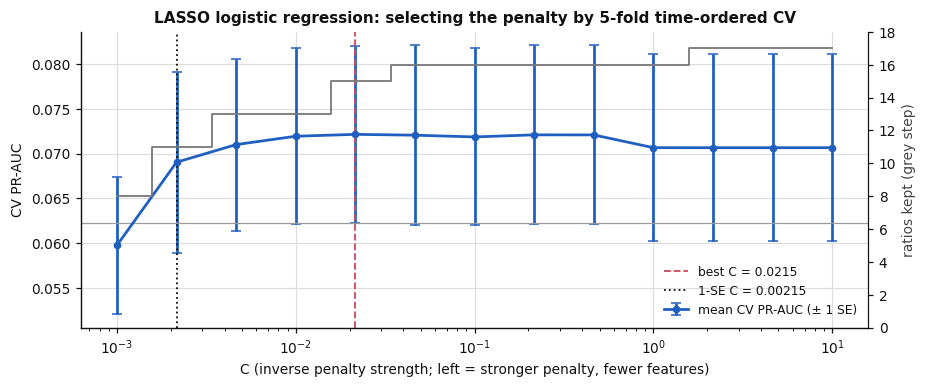

In [7]:
# Figure 7 — LASSO path: CV PR-AUC and number of ratios kept vs penalty strength
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.errorbar(path.C, path["CV PR-AUC (mean)"], yerr=path["PR-AUC (se)"], color=C_BASE, marker="o", ms=4,
            capsize=3, lw=1.8, label="mean CV PR-AUC (± 1 SE)")
ax.axvline(C_BEST, color=C_ALT, ls="--", lw=1.2, label=f"best C = {C_BEST:.3g}")
ax.axvline(C_1SE, color=INK, ls=":", lw=1.2, label=f"1-SE C = {C_1SE:.3g}")
ax.axhline(thresh, color="#9a9a9a", lw=0.8)
ax.set_xscale("log")
ax.set(xlabel="C (inverse penalty strength; left = stronger penalty, fewer features)", ylabel="CV PR-AUC",
       title="LASSO logistic regression: selecting the penalty by 5-fold time-ordered CV")
ax2 = ax.twinx()
ax2.step(path.C, path["ratios kept (of 17)"], where="mid", color="#7a7a7a", lw=1.2)
ax2.set_ylabel("ratios kept (grey step)", color="#444444")
ax2.set_ylim(0, 18); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig("figures/m08_fig1_lasso_path.png", dpi=250, bbox_inches="tight")
plt.show()

In [8]:
# Procedure 2 — filter selection: SelectKBest (ANOVA F) + L2 logistic, k chosen by the same CV
def kbest_pipe(k):
    return Pipeline([("features", FunctionTransformer(build_features)), ("pre", numeric_pre(NUM_FEATS)),
                     ("select", SelectKBest(f_classif, k=k)),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=5000))])

K_GRID = [3, 5, 8, 10, 13, "all"]
gk = GridSearchCV(kbest_pipe(5), {"select__k": K_GRID}, cv=folds, scoring="average_precision", n_jobs=1)
gk.fit(Xtr, ytr)
kb = pd.DataFrame({"k": [str(k) for k in K_GRID], "CV PR-AUC (mean)": gk.cv_results_["mean_test_score"],
                   "PR-AUC (sd)": gk.cv_results_["std_test_score"]}).set_index("k")
print(f"Best k = {gk.best_params_['select__k']}")
kb.round(4)

Best k = all


,CV PR-AUC (mean),PR-AUC (sd)
k,,
3,0.0307,0.0095
5,0.0489,0.0205
8,0.0390,0.0109
10,0.0407,0.0122
13,0.0397,0.0120
all,0.0706,0.0233


In [9]:
# Baseline summary on the 5 folds: the selected LASSO model against its references
base = fold_metrics(lasso_pipe(C_BEST))
full17 = fold_metrics(Pipeline([("features", FunctionTransformer(build_features)), ("pre", numeric_pre(NUM_FEATS)),
                                ("model", LogisticRegression(class_weight="balanced", max_iter=5000))]))
BASE_NAME = f"Baseline: LASSO logistic (C = {C_BEST:.3g})"
rows = []
for name, r in [(BASE_NAME, base), ("Logistic, all 17 ratios (no selection)", full17), ("Altman Z (1968, no fitting)", altman)]:
    rows.append({"model": name, "CV PR-AUC": r["ap"].mean(), "± 95% CI": t_half(r["ap"]),
                 "CV ROC-AUC": r["roc"].mean(), "recall in top 5%": r["rec"].mean()})
rows.append({"model": "No-skill (prevalence)", "CV PR-AUC": no_skill.mean(), "CV ROC-AUC": 0.5, "recall in top 5%": 0.05})
base_tab = pd.DataFrame(rows).set_index("model")
base_tab.round(4)

,CV PR-AUC,± 95% CI,CV ROC-AUC,recall in top 5%
model,,,,
Baseline: LASSO logistic (C = 0.0215),0.0722,0.0307,0.8853,0.4429
"Logistic, all 17 ratios (no selection)",0.0706,0.0324,0.8838,0.4429
"Altman Z (1968, no fitting)",0.0225,0.0078,0.8033,0.1418
No-skill (prevalence),0.0077,NaN,0.5000,0.0500


### 📝 Notes for the report (1a)
* **Replicates M06 exactly:** LASSO picks C = **0.0215**, keeping **15 of 17** ratios (drops retained earnings / assets
  and net income / assets, the redundant members of correlated pairs). CV PR-AUC **0.072 ± 0.031** (95% t-interval over
  the 5 folds), ROC-AUC 0.885, **recall in the riskiest 5% = 44.3%**.
* **Feature selection compared predictor subsets by CV PR-AUC:** the LASSO path is flat (0.071–0.072 from C = 0.005 to
  10; 0.060 with only 8 ratios at C = 0.001); the one-standard-error choice keeps 11 ratios at 0.069. The univariate
  filter (SelectKBest) is worse at every k below "all" (k = 3: 0.031, k = 5: 0.049, k = 8–13: 0.039–0.041, all: 0.071),
  because it keeps individually strong but redundant ratios and drops ones that help only in combination.
* **Against the references:** about **3.2×** Altman Z (0.022) and **9×** no-skill (0.008).
* **Next steps that motivated 1b (from M06 §4c):** the ratios' long tails and threshold effects hurt a linear model
  (log-scaling them alone lifted PR-AUC to 0.091), it cannot represent interactions, and class weighting cost PR-AUC.
  Tree ensembles address all three, and M06 pre-committed to adopting one only if it beats this baseline by ≥ 0.02.

## Section 1b — More complex models: random forest and gradient boosting
### 1b.1 Model choice
The baseline is linear in the (winsorized, scaled) ratios. Two things it cannot represent, both visible in M06:
* **Interactions.** High leverage is far more dangerous when the firm is also losing money or its market value is
  collapsing; a logistic model adds those effects instead of letting one amplify the other.
* **Thresholds and non-linear shapes.** Risk rises sharply once liabilities exceed assets or market value falls below
  liabilities, and the ratios have long tails that a single slope handles badly (M06 §4d: putting the ratios on a log
  scale alone lifted PR-AUC from 0.071 to 0.091).

Tree ensembles split the data on thresholds and stack splits on different features, so they learn interactions and
non-linear shapes automatically, and they are unaffected by monotone rescaling of the inputs.
* **Random forest (nb12):** many deep trees on bootstrap samples, each split choosing from a random subset of
  features; averaging them reduces variance. Few, forgiving hyperparameters.
* **Gradient boosting (nb13):** shallow trees added one at a time, each correcting the errors of the current ensemble.
  Usually the most accurate on tabular data, but more sensitive to tuning (learning rate × number of trees × depth).

Both use **exactly the baseline's pipeline** (same 17 ratios, winsorizing, median imputation + missing-indicators);
only the final estimator changes, so any difference in score comes from the model, not the inputs.

In [10]:
def make_model_pipe(model):
    # Identical preprocessing to the baseline; only the final estimator changes
    return Pipeline([("features", FunctionTransformer(build_features)), ("pre", numeric_pre(NUM_FEATS)),
                     ("model", model)])

### 1b.2 Decision rule, declared before any complex model is fit
M06 §4c committed to adopting a complex model **only if it beats the baseline by ≥ 0.02 PR-AUC**. We apply it with
the course's **paired per-fold rule** (nb14): every candidate is scored on the identical 5 folds, and for each
challenger we compute the five differences *d = challenger − baseline*.

| Outcome | Verdict |
|---|---|
| All 5 differences favor the challenger **and** their mean ≥ 0.02 | the challenger replaces the baseline |
| The signs disagree across folds | no winner: the simpler baseline stays |
| All 5 favor the same model but the mean is < 0.02 | practically equivalent: the simpler baseline stays |

**Why 0.02?** It is about one fold-to-fold standard deviation of the baseline's PR-AUC (0.022 in M06), and roughly a
quarter of the baseline's level; a smaller gain would not change which firms analysts review in any reliable way.

### 1b.3 Random forest: hyperparameter grid with 5-fold CV
| Hyperparameter | Values | What it controls |
|---|---|---|
| `n_estimators` | 300 (fixed) | number of trees; more trees only reduce noise, so it is fixed high rather than tuned |
| `max_features` | `"sqrt"` (4 of 21), 0.5 (half) | features tried at each split; fewer = more diverse, less correlated trees |
| `min_samples_leaf` | 5, 20, 50 | smallest leaf; larger = smoother probabilities, less overfitting to single failures |
| `class_weight` | none, `"balanced_subsample"` | whether the rare failures are up-weighted inside each tree's bootstrap sample |

12 combinations × 5 folds = 60 fits, scored by PR-AUC. `GridSearchCV` runs the full pipeline inside every fold.

In [11]:
RF_GRID = {"model__max_features": ["sqrt", 0.5],
           "model__min_samples_leaf": [5, 20, 50],
           "model__class_weight": [None, "balanced_subsample"]}
rf_pipe = make_model_pipe(RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=RANDOM_SEED))
t0 = time.time()
gs_rf = GridSearchCV(rf_pipe, RF_GRID, cv=folds, scoring=["average_precision", "roc_auc"],
                     refit="average_precision", n_jobs=-1)
gs_rf.fit(Xtr, ytr)
print(f"Random forest grid: {len(gs_rf.cv_results_['params'])} combinations × {len(folds)} folds in {time.time() - t0:.0f}s")

def grid_table(g, keys):
    r = g.cv_results_
    t = pd.DataFrame({k.replace("model__", ""): [str(p[k]) for p in r["params"]] for k in keys})
    split = np.column_stack([r[f"split{i}_test_average_precision"] for i in range(len(folds))])
    t["CV PR-AUC"] = r["mean_test_average_precision"]
    t["± 95% CI"] = [t_half(s) for s in split]
    t["CV ROC-AUC"] = r["mean_test_roc_auc"]
    t["fit time (s)"] = r["mean_fit_time"]
    return t.sort_values("CV PR-AUC", ascending=False).reset_index(drop=True)

rf_tab = grid_table(gs_rf, list(RF_GRID))
print("Best:", gs_rf.best_params_, f"CV PR-AUC {gs_rf.best_score_:.4f}")
rf_tab.round(4)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.che

Random forest grid: 12 combinations × 5 folds in 647s
Best: {'model__class_weight': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 50} CV PR-AUC 0.2247


,max_features,min_samples_leaf,class_weight,CV PR-AUC,± 95% CI,CV ROC-AUC,fit time (s)
0,0.5,50,None,0.2247,0.1420,0.9057,143.6053
1,0.5,20,None,0.2199,0.1502,0.8991,142.7841
2,sqrt,20,None,0.2146,0.1427,0.8976,48.0624
3,sqrt,50,None,0.2111,0.1269,0.9114,46.8893
4,sqrt,5,None,0.1975,0.1453,0.8979,49.5960
5,0.5,5,None,0.1867,0.1128,0.8974,142.5412
6,sqrt,50,balanced_subsample,0.1798,0.1229,0.9089,45.9516
7,sqrt,20,balanced_subsample,0.1666,0.1042,0.9012,50.5379
8,0.5,50,balanced_subsample,0.1662,0.1175,0.9030,84.9096
9,sqrt,5,balanced_subsample,0.1426,0.0908,0.8865,50.5830


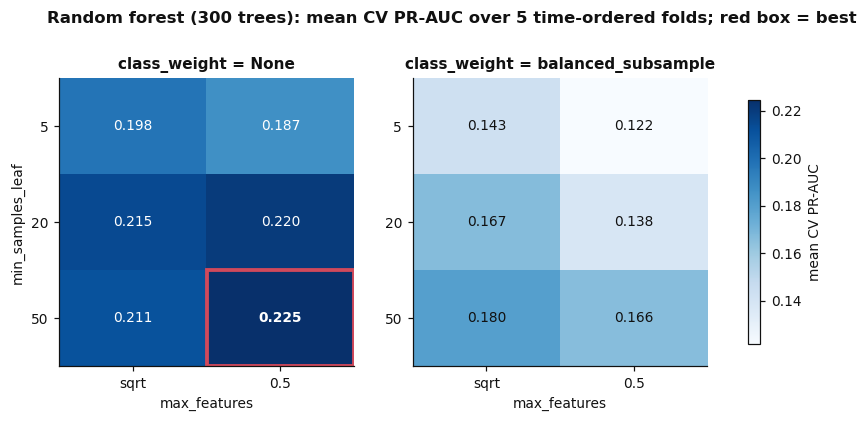

In [12]:
# Figure 2 — random forest grid (rows: min_samples_leaf, columns: max_features; one panel per class weighting)
def heat(ax, tab, row, col, rows, cols, title, vmin, vmax, best):
    M = np.array([[tab.loc[(tab[row] == str(r)) & (tab[col] == str(c)), "CV PR-AUC"].iloc[0] for c in cols] for r in rows])
    im = ax.imshow(M, cmap="Blues", vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(len(rows)):
        for j in range(len(cols)):
            ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > vmin + 0.6 * (vmax - vmin) else INK,
                    fontweight="bold" if (str(rows[i]), str(cols[j])) == best else "normal")
            if (str(rows[i]), str(cols[j])) == best:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=C_ALT, lw=2.5))
    ax.set_xticks(range(len(cols)), [str(c) for c in cols]); ax.set_yticks(range(len(rows)), [str(r) for r in rows])
    ax.set(title=title, xlabel=col, ylabel=row); ax.grid(False)
    return im

vmin, vmax = rf_tab["CV PR-AUC"].min(), rf_tab["CV PR-AUC"].max()
bp = gs_rf.best_params_
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for a, cw in zip(ax, [None, "balanced_subsample"]):
    sub = rf_tab[rf_tab.class_weight == str(cw)]
    best = (str(bp["model__min_samples_leaf"]), str(bp["model__max_features"])) if bp["model__class_weight"] == cw else None
    im = heat(a, sub, "min_samples_leaf", "max_features", [5, 20, 50], ["sqrt", 0.5],
              f"class_weight = {cw}", vmin, vmax, best)
ax[1].set_ylabel("")
fig.colorbar(im, ax=ax, shrink=0.85, label="mean CV PR-AUC")
fig.suptitle("Random forest (300 trees): mean CV PR-AUC over 5 time-ordered folds; red box = best", fontweight="bold", y=1.06)
fig.savefig("figures/m08_fig2_rf_grid.png", dpi=250, bbox_inches="tight")
plt.show()

### 📝 Notes for the report (random forest tuning)
* **Every one of the 12 random-forest settings beats the baseline** (0.122–0.225 vs 0.072).
* **Best: `max_features = 0.5`, `min_samples_leaf = 50`, no class weighting: CV PR-AUC 0.225**, ROC-AUC 0.906.
* **Class weighting hurts in every cell** (all 6 weighted settings are below all 6 unweighted ones, 0.122–0.180 vs
  0.187–0.225). Up-weighting the rare failures makes leaves predict "risky" too readily and blurs the top of the list,
  the same pattern M06 §4d found for logistic regression.
* **Larger leaves help:** going from 5 to 50 samples per leaf raises PR-AUC in all four panel columns. With only
  ~450 failures, small leaves memorize individual failing firms; larger leaves average them into smoother probabilities.
* **Performance vs complexity:** the best four unweighted settings sit within 0.014 of each other (0.211–0.225), far
  inside the fold-to-fold noise (± 0.13–0.15). `max_features = "sqrt"` with 20–50 leaves scores 0.211–0.215 at about
  **one-third of the fit time** (43 s vs 123 s per fold). We keep the best-mean setting as the course rule asks, and note
  the sqrt version as an equally defensible, cheaper choice.
* **Grid boundary:** the best `min_samples_leaf` (50) is the largest value tried, so the optimum may lie beyond it;
  extending the grid (100, 200) is a next step.

**Figure 2 caption (suggested):** *Random forest (300 trees) tuning grid: mean CV PR-AUC over the 5 time-ordered folds
for each combination of features-per-split and minimum leaf size, without (left) and with (right) balanced class
weights. Red box = best setting.*

### 1b.4 Gradient boosting: hyperparameter grid with 5-fold CV
`GradientBoostingClassifier` as in nb13. Learning rate and number of trees trade off (a smaller step needs more trees),
and depth sets how many features each tree can combine, so these three are searched jointly.

| Hyperparameter | Values | What it controls |
|---|---|---|
| `n_estimators` | 100, 300 | number of boosting rounds |
| `learning_rate` | 0.05, 0.1 | how much each new tree corrects the ensemble; smaller = slower, more regularized |
| `max_depth` | 2, 3, 4 | interaction order: depth 2 = pairs of features, depth 4 = up to four-way interactions |
| `subsample`, `max_features` | 0.8, 0.5 (fixed) | stochastic boosting: each tree sees 80% of rows and each split half the features; fixed at nb13's pick to regularize and keep run time manageable |

12 combinations × 5 folds = 60 fits. Gradient boosting has no `class_weight` option; M06 §4d found balanced weights
*lowered* PR-AUC for the logistic model (0.094 without vs 0.071 with), and the random-forest grid above tests weighting
directly, so boosting is left unweighted.

In [13]:
GB_GRID = {"model__n_estimators": [100, 300],
           "model__learning_rate": [0.05, 0.1],
           "model__max_depth": [2, 3, 4]}
gb_pipe = make_model_pipe(GradientBoostingClassifier(subsample=0.8, max_features=0.5, random_state=RANDOM_SEED))
t0 = time.time()
gs_gb = GridSearchCV(gb_pipe, GB_GRID, cv=folds, scoring=["average_precision", "roc_auc"],
                     refit="average_precision", n_jobs=-1)
gs_gb.fit(Xtr, ytr)
print(f"Gradient boosting grid: {len(gs_gb.cv_results_['params'])} combinations × {len(folds)} folds in {time.time() - t0:.0f}s")
gb_tab = grid_table(gs_gb, list(GB_GRID))
print("Best:", gs_gb.best_params_, f"CV PR-AUC {gs_gb.best_score_:.4f}")
gb_tab.round(4)

Gradient boosting grid: 12 combinations × 5 folds in 239s
Best: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 300} CV PR-AUC 0.1629


,n_estimators,learning_rate,max_depth,CV PR-AUC,± 95% CI,CV ROC-AUC,fit time (s)
0,300,0.05,2,0.1629,0.0791,0.9186,31.1062
1,100,0.05,2,0.1616,0.0960,0.9153,10.2874
2,100,0.1,2,0.1488,0.0957,0.9129,11.0988
3,100,0.05,3,0.1375,0.0545,0.9152,15.4652
4,300,0.05,3,0.1247,0.0633,0.9100,45.6484
5,100,0.1,3,0.1202,0.0555,0.9116,17.5870
6,300,0.1,2,0.1134,0.0455,0.9067,35.6458
7,100,0.05,4,0.1095,0.0390,0.9175,19.4527
8,100,0.1,4,0.0983,0.0416,0.9053,23.4213
9,300,0.05,4,0.0899,0.0288,0.9049,65.4236


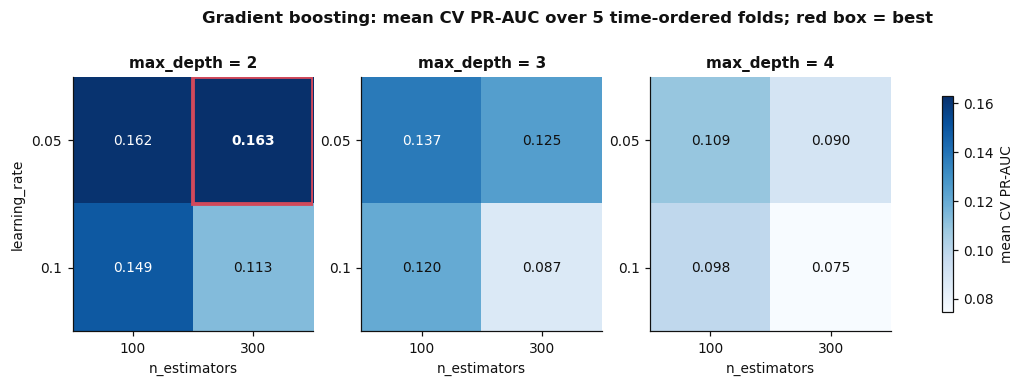

In [14]:
# Figure 3 — gradient boosting grid (rows: learning rate, columns: trees; one panel per depth)
vmin, vmax = gb_tab["CV PR-AUC"].min(), gb_tab["CV PR-AUC"].max()
bp = gs_gb.best_params_
fig, ax = plt.subplots(1, 3, figsize=(12, 3.0))
for a, d in zip(ax, [2, 3, 4]):
    sub = gb_tab[gb_tab.max_depth == str(d)]
    best = (str(bp["model__learning_rate"]), str(bp["model__n_estimators"])) if bp["model__max_depth"] == d else None
    im = heat(a, sub, "learning_rate", "n_estimators", [0.05, 0.1], [100, 300], f"max_depth = {d}", vmin, vmax, best)
for a in ax[1:]:
    a.set_ylabel("")
fig.colorbar(im, ax=ax, shrink=0.85, label="mean CV PR-AUC")
fig.suptitle("Gradient boosting: mean CV PR-AUC over 5 time-ordered folds; red box = best", fontweight="bold", y=1.08)
fig.savefig("figures/m08_fig3_gb_grid.png", dpi=250, bbox_inches="tight")
plt.show()

### 📝 Notes for the report (gradient boosting tuning)
* **Best: `learning_rate = 0.05`, `max_depth = 2`, `n_estimators = 300`: CV PR-AUC 0.163**, ROC-AUC 0.919. Range across
  the grid 0.075–0.163; even the worst setting (300 trees, lr 0.1, depth 4: 0.075) edges the baseline's 0.072, but only
  the shallow settings beat it clearly.
* **Clear overfitting pattern:** scores fall as depth rises (best per depth: 0.163 at depth 2, 0.138 at depth 3, 0.110
  at depth 4) and as learning rate × trees grows (at depth 3–4, 300 trees at lr 0.1 is the worst cell). With ~450
  failures, deep or fast boosting starts fitting individual failing firms. **Shallow trees (pairs of features) are
  enough:** the useful interactions are two-way, e.g. leverage × market value.
* **Performance vs complexity:** 100 trees at lr 0.05, depth 2 scores **0.162**, only 0.001 below the best at about a
  third of the fit time (8 s vs 26 s); the difference is noise.
* **Grid boundary:** the best cell is the most conservative corner (smallest learning rate, shallowest trees), so a
  slower learning rate (0.02) with more trees, or depth 1, may do better; that is a next step.

**Figure 3 caption (suggested):** *Gradient boosting tuning grid (stochastic boosting: 80% row subsample, half the
features per split): mean CV PR-AUC over the 5 time-ordered folds by learning rate and number of trees, for tree depths
2–4. Red box = best setting.*

### 1b.5 Final comparison: tuned models vs the baseline on identical folds
Each tuned model is refit fold by fold with its best hyperparameters, giving per-fold scores paired with the
baseline's. Means come with 95% Student's *t* half-widths (k = 5, df = 4, nb08). The intervals are approximate:
expanding-window folds share training rows, so the five scores are not independent.

In [15]:
RF_BEST = {k.replace("model__", ""): v for k, v in gs_rf.best_params_.items()}
GB_BEST = {k.replace("model__", ""): v for k, v in gs_gb.best_params_.items()}
rf = fold_metrics(make_model_pipe(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_SEED, **RF_BEST)))
gb = fold_metrics(make_model_pipe(GradientBoostingClassifier(subsample=0.8, max_features=0.5, random_state=RANDOM_SEED, **GB_BEST)))

RF_NAME, GB_NAME, ALT_NAME = "Random forest (tuned)", "Gradient boosting (tuned)", "Altman Z (1968, no fitting)"
RESULTS = {BASE_NAME: base, RF_NAME: rf, GB_NAME: gb, ALT_NAME: altman}
fmt = lambda x: f"{x.mean():.4f} ± {t_half(x):.4f}"
comp = pd.DataFrame({name: {"CV PR-AUC (± 95% CI)": fmt(r["ap"]), "CV ROC-AUC (± 95% CI)": fmt(r["roc"]),
                            "recall in top 5% (± 95% CI)": fmt(r["rec"]), "fit time per fold (s)": f"{r['fit_s']:.1f}"}
                     for name, r in RESULTS.items()}).T
comp.loc["No-skill (prevalence)"] = [f"{no_skill.mean():.4f}", "0.5000", "0.0500", "0.0"]
print("Best random forest:", RF_BEST)
print("Best gradient boosting:", GB_BEST)
comp

Best random forest: {'class_weight': None, 'max_features': 0.5, 'min_samples_leaf': 50}
Best gradient boosting: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300}


,CV PR-AUC (± 95% CI),CV ROC-AUC (± 95% CI),recall in top 5% (± 95% CI),fit time per fold (s)
Baseline: LASSO logistic (C = 0.0215),0.0722 ± 0.0307,0.8853 ± 0.0493,0.4429 ± 0.1749,0.3
Random forest (tuned),0.2247 ± 0.1420,0.9057 ± 0.0447,0.5992 ± 0.1117,14.7
Gradient boosting (tuned),0.1629 ± 0.0791,0.9186 ± 0.0302,0.6107 ± 0.1750,16.0
"Altman Z (1968, no fitting)",0.0225 ± 0.0078,0.8033 ± 0.0420,0.1418 ± 0.0872,0.0
No-skill (prevalence),0.0077,0.5000,0.0500,0.0


In [16]:
# Per-fold PR-AUC: the paired scores behind every mean
pf = pd.DataFrame({name: r["ap"] for name, r in RESULTS.items()}, index=[f"validate {v}" for v in FOLD_YEARS]).T
pf.loc["no-skill"] = no_skill
pf.loc["(failures in validation year)"] = [int(ytr[va].sum()) for _, va in folds]
pf.round(4)

,validate 2009,validate 2010,validate 2011,validate 2012,validate 2013
Baseline: LASSO logistic (C = 0.0215),0.0602,0.0644,0.0834,0.1087,0.0441
Random forest (tuned),0.1132,0.1446,0.3434,0.3524,0.1697
Gradient boosting (tuned),0.1006,0.1596,0.2527,0.1953,0.1062
"Altman Z (1968, no fitting)",0.0155,0.0295,0.0209,0.0285,0.0181
no-skill,0.0061,0.0097,0.0071,0.0075,0.0080
(failures in validation year),23.0000,35.0000,25.0000,26.0000,28.0000


In [17]:
# Paired per-fold rule (nb14) against the margin declared in M06 (§1b.2)
def paired_rule(challenger, reference, margin=MARGIN):
    d = challenger - reference
    if np.all(d > 0) and d.mean() >= margin:
        return d, "challenger wins: all folds favor it and the mean clears the margin"
    if np.all(d < 0) and -d.mean() >= margin:
        return d, "reference wins: all folds favor it and the mean clears the margin"
    if len(set(np.sign(d))) > 1:
        return d, "no winner: the folds disagree; the simpler model stays"
    return d, "practically equivalent: same direction but inside the margin; the simpler model stays"

PAIRS = [(RF_NAME, BASE_NAME), (GB_NAME, BASE_NAME), (GB_NAME, RF_NAME), (RF_NAME, ALT_NAME), (GB_NAME, ALT_NAME)]
prow, diffs = [], {}
for ch, ref in PAIRS:
    d, verdict = paired_rule(RESULTS[ch]["ap"], RESULTS[ref]["ap"])
    diffs[(ch, ref)] = d
    prow.append({"challenger − reference": f"{ch} − {ref.split(':')[0]}",
                 **{f"Δ {v}": x for v, x in zip(FOLD_YEARS, d)},
                 "mean Δ": d.mean(), "± 95% CI": t_half(d), "folds > 0": int((d > 0).sum()),
                 "verdict (margin 0.02)": verdict})
paired = pd.DataFrame(prow).set_index("challenger − reference")
pd.set_option("display.max_colwidth", 90)
paired.round(4)

,Δ 2009,Δ 2010,Δ 2011,Δ 2012,Δ 2013,mean Δ,± 95% CI,folds > 0,verdict (margin 0.02)
challenger − reference,,,,,,,,,
Random forest (tuned) − Baseline,0.0530,0.0802,0.2600,0.2438,0.1256,0.1525,0.1174,5,challenger wins: all folds favor it and the mean clears the margin
Gradient boosting (tuned) − Baseline,0.0404,0.0952,0.1693,0.0867,0.0620,0.0907,0.0607,5,challenger wins: all folds favor it and the mean clears the margin
Gradient boosting (tuned) − Random forest (tuned),-0.0125,0.0150,-0.0908,-0.1571,-0.0635,-0.0618,0.0839,1,no winner: the folds disagree; the simpler model stays
"Random forest (tuned) − Altman Z (1968, no fitting)",0.0977,0.1151,0.3225,0.3240,0.1517,0.2022,0.1393,5,challenger wins: all folds favor it and the mean clears the margin
"Gradient boosting (tuned) − Altman Z (1968, no fitting)",0.0851,0.1300,0.2318,0.1669,0.0881,0.1404,0.0759,5,challenger wins: all folds favor it and the mean clears the margin


In [18]:
# Champion: the baseline unless a complex model wins outright under the rule; between two winners, the higher mean
winners = [ch for ch in (RF_NAME, GB_NAME) if paired_rule(RESULTS[ch]["ap"], base["ap"])[1].startswith("challenger")]
if len(winners) == 2:
    d, verdict = paired_rule(gb["ap"], rf["ap"])
    CHAMPION = GB_NAME if verdict.startswith("challenger") else RF_NAME   # RF is the simpler, faster-to-tune ensemble
elif winners:
    CHAMPION = winners[0]
else:
    CHAMPION = BASE_NAME
BEST_COMPLEX = RF_NAME if rf["ap"].mean() >= gb["ap"].mean() else GB_NAME
print(f"Champion carried to M09/M10: {CHAMPION}")
print(f"Best complex model by mean CV PR-AUC: {BEST_COMPLEX}")

Champion carried to M09/M10: Random forest (tuned)
Best complex model by mean CV PR-AUC: Random forest (tuned)


### 📝 Notes for the report (1b model selection and final comparison)
**The main result.**
* **Tuned random forest: CV PR-AUC 0.225 ± 0.142**, ROC-AUC 0.906, recall in the riskiest 5% = **59.9%**.
  **Tuned gradient boosting: 0.163 ± 0.079**, ROC-AUC 0.919, recall in the riskiest 5% = 61.1%.
  **Baseline LASSO: 0.072 ± 0.031**, ROC-AUC 0.885, 44.3%. Altman Z 0.022; no-skill 0.008.
* **Paired rule against the 0.02 margin declared in M06:**
  * Random forest − baseline: **+0.053, +0.080, +0.260, +0.244, +0.126** (2009–2013). **5 of 5 folds favor the
    forest; mean +0.153 (95% CI ± 0.117), far above 0.02. → The random forest replaces the baseline.**
  * Gradient boosting − baseline: +0.040, +0.095, +0.169, +0.087, +0.062. 5 of 5 folds; mean **+0.091 (± 0.061)**.
    → Also clears the margin.
  * Gradient boosting − random forest: −0.013, **+0.015**, −0.091, −0.157, −0.064 → the folds disagree, so under nb14's
    rule neither ensemble has earned displacing the other. We carry the **random forest** forward: it leads on the mean
    by 0.062 and in 4 of 5 folds, and it has fewer interacting hyperparameters to keep tuned. Gradient boosting stays as
    the documented runner-up.
* **Why the intervals are wide:** the forest's gain is concentrated in 2011–2012 (PR-AUC 0.34–0.35 vs 0.11–0.17 in other
  years), and each year has only 23–35 failures. The paired view is what makes the conclusion firm: the gain is
  positive in every year, including the worst one (+0.053 in 2009).
* **Honest caveats.** (1) The grids were scored on the same 5 folds used to pick the winner, so the best-of-12 score is
  slightly optimistic; the baseline's C was chosen the same way, and the gain (+0.15) is far larger than that selection
  effect. (2) Fold scores share training years, so the t-intervals are approximate (nb14). The unbiased check comes at
  M09, on the locked 2014–2016 validation years, with the 2017–2018 test years opened once at the end.

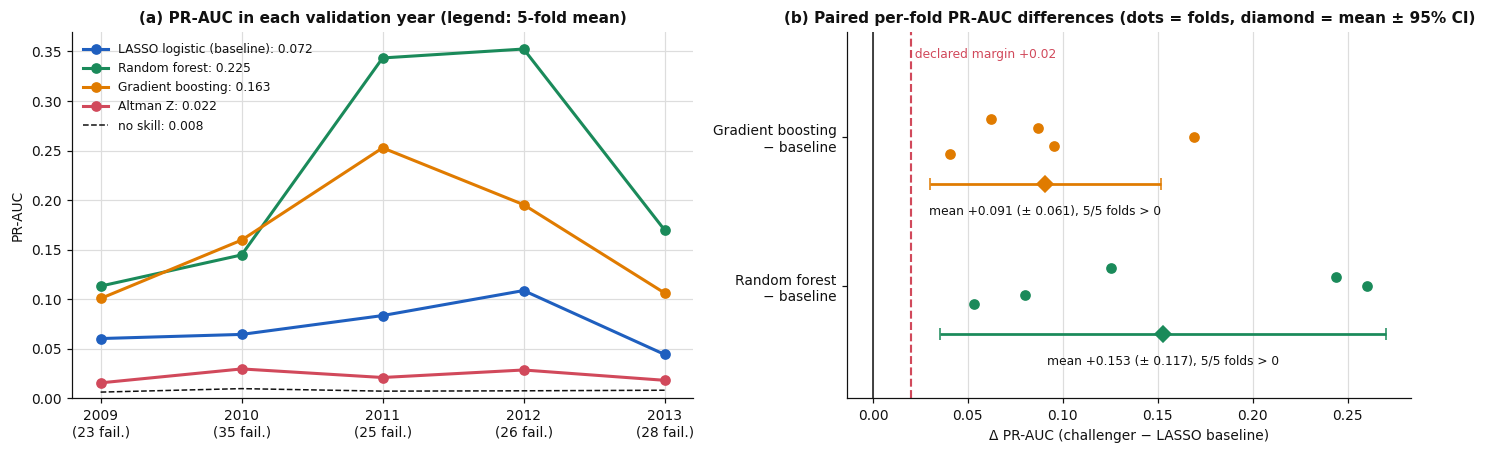

In [19]:
# Figure 4 — (a) PR-AUC by validation year, (b) paired differences vs the baseline with the declared margin
COLORS = {BASE_NAME: C_BASE, RF_NAME: C_RF, GB_NAME: C_GB, ALT_NAME: C_ALT}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.1, 1]))
for name, r in RESULTS.items():
    ax[0].plot(FOLD_YEARS, r["ap"], marker="o", lw=2, color=COLORS[name],
               label=f"{name.split(' (')[0] if name != BASE_NAME else 'LASSO logistic (baseline)'}: {r['ap'].mean():.3f}")
ax[0].plot(FOLD_YEARS, no_skill, color=INK, ls="--", lw=1, label=f"no skill: {no_skill.mean():.3f}")
ax[0].set_xticks(FOLD_YEARS, [f"{v}\n({int(ytr[va].sum())} fail.)" for v, (_, va) in zip(FOLD_YEARS, folds)])
ax[0].set(title="(a) PR-AUC in each validation year (legend: 5-fold mean)", ylabel="PR-AUC", ylim=(0, None))
ax[0].legend(fontsize=8, loc="upper left")

for i, (ch, col) in enumerate([(RF_NAME, C_RF), (GB_NAME, C_GB)]):
    d = diffs[(ch, BASE_NAME)]
    yy = np.full(5, i) + np.linspace(-0.12, 0.12, 5)
    ax[1].scatter(d, yy, color=col, s=36, zorder=3)
    ax[1].errorbar(d.mean(), i - 0.32, xerr=t_half(d), fmt="D", color=col, ms=7, capsize=4, lw=1.8, zorder=3)
    ax[1].text(d.mean(), i - 0.52, f"mean {d.mean():+.3f} (± {t_half(d):.3f}), {int((d > 0).sum())}/5 folds > 0",
               ha="center", fontsize=8)
ax[1].axvline(0, color=INK, lw=1)
ax[1].axvline(MARGIN, color=C_ALT, ls="--", lw=1.4)
ax[1].text(MARGIN, 1.55, f" declared margin +{MARGIN}", color=C_ALT, fontsize=8, va="center")
ax[1].set_yticks([0, 1], ["Random forest\n− baseline", "Gradient boosting\n− baseline"])
ax[1].set_ylim(-0.75, 1.7)
ax[1].set(title="(b) Paired per-fold PR-AUC differences (dots = folds, diamond = mean ± 95% CI)",
          xlabel="Δ PR-AUC (challenger − LASSO baseline)")
ax[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("figures/m08_fig4_comparison.png", dpi=250, bbox_inches="tight")
plt.show()

### 📝 Notes for the report
**Figure 4 caption (suggested):** *(a) PR-AUC of each model in each validation year (each fold trains only on earlier
years); legend gives the 5-fold mean. (b) Paired per-fold PR-AUC differences against the LASSO baseline: dots are the
five folds, diamonds the mean with its 95% t-interval; dashed line = the 0.02 margin declared in M06 before any complex
model was fit. Both ensembles clear it in every fold.*

### 1b.6 What the gain means in practice, and what drives the tuned model
**Practical yardstick.** Pooling the out-of-fold predictions for 2009–2013, how many of the next year's bankruptcies
fall in the riskiest 5% of each year's firms? The pooled precision–recall curves show the same thing at every review
depth.

**Drivers.** Permutation importance of the best complex model on the last fold (trained on 1999–2012, scored on 2013):
shuffle one ratio at a time in the held-out year and measure how much PR-AUC drops. It is computed on held-out data,
so unlike impurity importance it is not inflated for features the trees merely split on often. Permuting a momentum
ratio also shuffles its missing-indicator, since the indicator is derived from it.

In [20]:
caught = []
for name, r in RESULTS.items():
    n_c = sum(int(round(recall_at_top(ytr[va], r["oof"][va]) * ytr[va].sum())) for _, va in folds)
    caught.append({"model": name, "failures in top 5% (2009–2013)": n_c,
                   "of all failures": int(sum(ytr[va].sum() for _, va in folds)),
                   "recall in top 5% (pooled)": n_c / sum(ytr[va].sum() for _, va in folds),
                   "precision in riskiest 1% (pooled)": np.mean(np.concatenate(
                       [ytr[va][np.argsort(-r["oof"][va])[:int(np.ceil(0.01 * len(va)))]] for _, va in folds]))})
caught = pd.DataFrame(caught).set_index("model")
caught.round(3)

,failures in top 5% (2009–2013),of all failures,recall in top 5% (pooled),precision in riskiest 1% (pooled)
model,,,,
Baseline: LASSO logistic (C = 0.0215),60,137,0.438,0.077
Random forest (tuned),81,137,0.591,0.232
Gradient boosting (tuned),82,137,0.599,0.199
"Altman Z (1968, no fitting)",20,137,0.146,0.011


### 📝 Notes for the report (practical significance)
* **Watch-list yardstick (riskiest 5% of each year's firms, 2009–2013 pooled, 137 bankruptcies):** random forest
  catches **81**, gradient boosting **82**, the LASSO baseline **60**, Altman Z **20**. Moving from the baseline to the
  forest means about **21 more bankruptcies caught (+35%) with the same review effort**, and four times as many as the
  industry-standard Altman screen.
* **Where the forest's PR-AUC edge comes from: the very top of the list.** At 5% depth the two ensembles catch the same
  number of failures, but among the **riskiest 1%** of firms, **23%** of the forest's picks actually fail, vs
  20% for gradient boosting, **8%** for the baseline and 1% for Altman Z. The forest's first
  flags are the ones an analyst checks first, so it wastes the least review time there.
* **Pooled vs per-fold numbers:** the pooled average precision in Figure 5a (0.201 forest, 0.143 boosting, 0.059
  baseline) is lower than the 5-fold means because pooling mixes years with different failure rates. Compare models
  within one view, not across views.

In [21]:
# Permutation importance of the best complex model on the last fold (train 1999–2012, held-out 2013)
best_pipe = (make_model_pipe(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_SEED, **RF_BEST))
             if BEST_COMPLEX == RF_NAME else
             make_model_pipe(GradientBoostingClassifier(subsample=0.8, max_features=0.5, random_state=RANDOM_SEED, **GB_BEST)))
tr, va = folds[-1]
best_pipe.fit(Xtr.iloc[tr], ytr[tr])
F_va = build_features(Xtr.iloc[va])[NUM_FEATS]
pi = permutation_importance(best_pipe[1:], F_va, ytr[va], scoring="average_precision",
                            n_repeats=10, random_state=RANDOM_SEED, n_jobs=1)
imp = pd.DataFrame({"PR-AUC drop (mean)": pi.importances_mean, "sd": pi.importances_std},
                   index=NUM_FEATS).sort_values("PR-AUC drop (mean)", ascending=False)
print(f"{BEST_COMPLEX}: PR-AUC on 2013 with nothing shuffled = {average_precision_score(ytr[va], best_pipe.predict_proba(Xtr.iloc[va])[:, 1]):.4f}")
imp.round(4)

Random forest (tuned): PR-AUC on 2013 with nothing shuffled = 0.1697


,PR-AUC drop (mean),sd
Market value / liabilities,0.1390,0.0053
Log market value,0.0897,0.0028
Log total assets,0.0765,0.0167
Working capital / assets,0.0436,0.0102
EBITDA / liabilities,0.0285,0.0097
EBIT / assets,0.0268,0.0087
Change in liabilities / assets,0.0247,0.0185
Sales growth,0.0135,0.0083
Net income / assets,0.0110,0.0035
Current ratio,0.0102,0.0081


### 📝 Notes for the report (what drives the forest)
* **Top drivers on held-out 2013 (drop in PR-AUC when shuffled, from 0.170):** market value / liabilities **0.139**,
  log market value **0.090**, log total assets **0.077**, working capital / assets 0.044, EBITDA / liabilities 0.029,
  EBIT / assets 0.027, change in liabilities / assets 0.025.
* **Reading:** the market's verdict dominates. How far equity value covers debt (Altman's 4th ratio, also the strongest
  single signal in M06) and the firm's market size come first, then liquidity, then operating profitability, then the
  momentum signal that leverage is rising. This matches the credit-analysis logic and the M06 univariate screen.
* **Caveat for correlated ratios:** liabilities / assets shows ~0 importance even though it is a strong signal on its
  own (M06 AUC 0.77). Shuffling it changes little because market value / liabilities, EBITDA / liabilities and the
  change in leverage carry the same information. Permutation importance measures *unique* contribution, not relevance;
  read correlated ratios as a group. Importance is also from one fold (2013, 28 failures), so the exact order of the
  smaller ones is noisy.

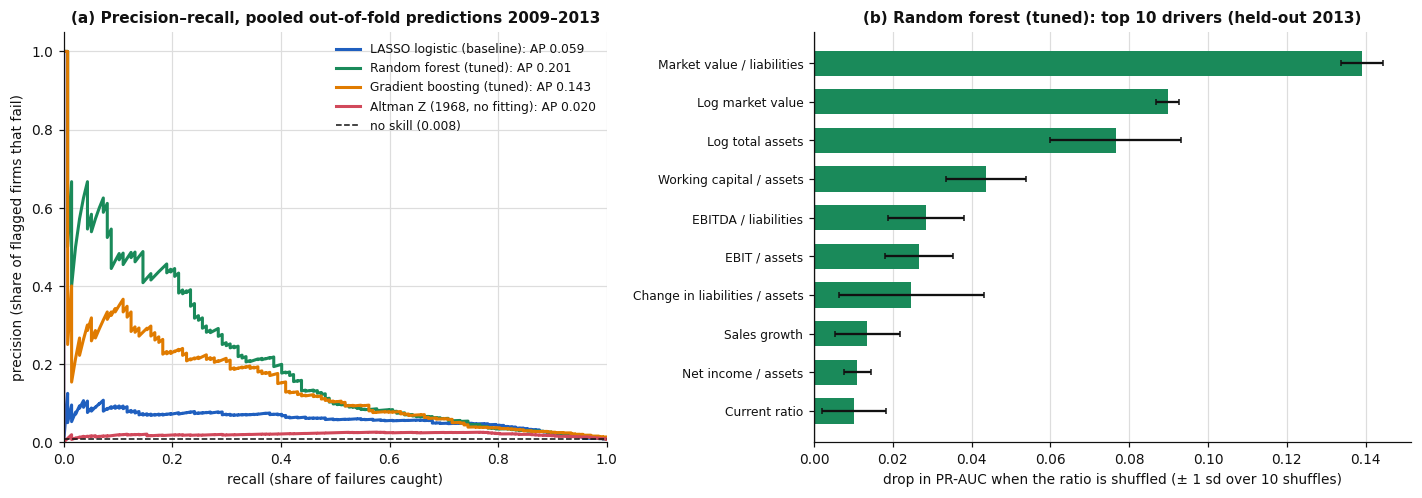

In [22]:
# Figure 5 — (a) pooled out-of-fold precision–recall curves, (b) permutation importance of the best complex model
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1, 1.1]))
mask = ~np.isnan(base["oof"])
for name, r in RESULTS.items():
    prec, rec, _ = precision_recall_curve(ytr[mask], r["oof"][mask])
    ax[0].plot(rec, prec, color=COLORS[name], lw=2,
               label=f"{name if name != BASE_NAME else 'LASSO logistic (baseline)'}: AP {average_precision_score(ytr[mask], r['oof'][mask]):.3f}")
ax[0].axhline(ytr[mask].mean(), color=INK, ls="--", lw=1, label=f"no skill ({ytr[mask].mean():.3f})")
ax[0].set(xlabel="recall (share of failures caught)", ylabel="precision (share of flagged firms that fail)",
          title="(a) Precision–recall, pooled out-of-fold predictions 2009–2013", xlim=(0, 1), ylim=(0, None))
ax[0].legend(fontsize=8)

top = imp.head(10).iloc[::-1]
ax[1].barh(top.index, top["PR-AUC drop (mean)"], xerr=top["sd"], color=COLORS[BEST_COMPLEX], height=0.65,
           capsize=2, ecolor=INK)
ax[1].axvline(0, color=INK, lw=0.8)
ax[1].set(xlabel="drop in PR-AUC when the ratio is shuffled (± 1 sd over 10 shuffles)",
          title=f"(b) {BEST_COMPLEX}: top 10 drivers (held-out 2013)")
ax[1].tick_params(axis="y", labelsize=8)
ax[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("figures/m08_fig5_champion.png", dpi=250, bbox_inches="tight")
plt.show()

### 📝 Notes for the report
**Figure 5 caption (suggested):** *(a) Precision–recall curves from pooled out-of-fold predictions for 2009–2013: the
random forest keeps precision near 0.4–0.6 for the first 10–20% of failures, where the baseline stays below 0.1.
(b) Permutation importance of the tuned random forest on the held-out 2013 year: drop in PR-AUC when each ratio is
shuffled (top 10; ± 1 sd over 10 shuffles).*

### 📝 1b. Interpretation, model selection and next steps (write-up material)
**What we tested.** Two tree ensembles on exactly the baseline's pipeline and folds: a random forest (12 settings of
features-per-split, leaf size and class weighting) and gradient boosting (12 settings of trees, learning rate and depth),
each tuned with `GridSearchCV` on 5 time-ordered folds and scored by PR-AUC.

**Which configuration and why.** Random forest, 300 trees, `max_features = 0.5`, `min_samples_leaf = 50`, no class
weighting: the best mean CV PR-AUC (0.225). Large leaves and no up-weighting give smoother, better-ranked probabilities;
the cheaper `sqrt` setting is statistically indistinguishable (0.211–0.215).

**Compared with the baseline.** PR-AUC rises from **0.072 to 0.225 (about 3×)**, better in all 5 validation years,
with a mean paired gain of +0.153, far above the 0.02 margin declared in M06. ROC-AUC rises from 0.885 to 0.906. Gradient
boosting also clears the margin (+0.091) but trails the forest in 4 of 5 years.

**In practical terms.** Reviewing the riskiest 5% of firms each year, the forest flags about **3 in 5 of next year's
bankruptcies (59–60%) instead of 2 in 5 (44%)**: 81 instead of 60 of the 137 failures in 2009–2013, and 4× the
20 caught by the Altman Z-score. Its very first flags are much cleaner too (riskiest 1%: see the table above).

**Why the ensembles win.** They capture what the linear model could not: thresholds (risk jumps once market value falls
below liabilities) and interactions among market value, size, liquidity and profitability. Both tuning grids prefer the
most regularized settings (large leaves; shallow, slow boosting), which says the signal is a few strong, mostly
two-way patterns, not intricate high-order structure.

**Next steps.**
1. **Extend the grids past their boundaries** (forest `min_samples_leaf` 100–200; boosting depth 1 and learning rate
   0.02 with more trees), since both optima sit at a grid edge.
2. **Confirm on the locked 2014–2016 validation years** (M09), then open the 2017–2018 test years once, with bootstrap
   confidence intervals.
3. **Calibrate and set a threshold.** Forest scores rank well but are not calibrated probabilities; choose a cost-based
   review threshold (a missed bankruptcy costs far more than a false alarm).
4. **Industry (`Division`)** remains untested as an input (M06 found failure rates of 0.5–1.2% by sector).

**Caveats.** Fold-to-fold variation is large (only 23–35 failures per year); grid scores are slightly optimistic because
selection and scoring share folds; importance is a unique-contribution measure, not a causal effect.

### 1b.7 Key numbers for the report
Copy these into Sections 1a–1b of `22_complex_models.pdf`.

In [23]:
rf_tab_best, gb_tab_best = rf_tab.iloc[0], gb_tab.iloc[0]
d_rf, d_gb = diffs[(RF_NAME, BASE_NAME)], diffs[(GB_NAME, BASE_NAME)]
facts = {
    "training years / failures": f"1999–{TRAIN_END}: {len(train):,} firm-years, {int(ytr.sum())} failures ({ytr.mean():.2%})",
    "baseline (LASSO) C / ratios kept": f"{C_BEST:.3g} / {nnz[best_i]} of 17",
    "baseline CV PR-AUC / ROC-AUC / top-5% recall": f"{fmt(base['ap'])} / {base['roc'].mean():.3f} / {base['rec'].mean():.1%}",
    "SelectKBest best k / CV PR-AUC": f"{gk.best_params_['select__k']} / {gk.best_score_:.4f}",
    "Altman Z CV PR-AUC / no-skill": f"{altman['ap'].mean():.4f} / {no_skill.mean():.4f}",
    "RF grid range (CV PR-AUC)": f"{rf_tab['CV PR-AUC'].min():.4f} – {rf_tab['CV PR-AUC'].max():.4f}",
    "RF best params": str(RF_BEST),
    "RF tuned CV PR-AUC / ROC-AUC / top-5% recall": f"{fmt(rf['ap'])} / {rf['roc'].mean():.3f} / {rf['rec'].mean():.1%}",
    "GB grid range (CV PR-AUC)": f"{gb_tab['CV PR-AUC'].min():.4f} – {gb_tab['CV PR-AUC'].max():.4f}",
    "GB best params": str(GB_BEST),
    "GB tuned CV PR-AUC / ROC-AUC / top-5% recall": f"{fmt(gb['ap'])} / {gb['roc'].mean():.3f} / {gb['rec'].mean():.1%}",
    "RF − baseline (paired)": f"mean {d_rf.mean():+.4f} ± {t_half(d_rf):.4f}, {int((d_rf > 0).sum())}/5 folds > 0 → {paired.iloc[0]['verdict (margin 0.02)']}",
    "GB − baseline (paired)": f"mean {d_gb.mean():+.4f} ± {t_half(d_gb):.4f}, {int((d_gb > 0).sum())}/5 folds > 0 → {paired.iloc[1]['verdict (margin 0.02)']}",
    "GB − RF (paired)": f"mean {diffs[(GB_NAME, RF_NAME)].mean():+.4f} → {paired.iloc[2]['verdict (margin 0.02)']}",
    "champion": CHAMPION,
    "failures caught in top 5% (pooled 2009–2013)": "; ".join(f"{k.split(':')[0].split(' (')[0]}: {v}" for k, v in caught["failures in top 5% (2009–2013)"].items())
                                                     + f" (of {caught['of all failures'].iloc[0]})",
    "top 3 drivers (permutation, 2013)": ", ".join(imp.index[:3]),
}
pd.Series(facts, name="value").to_frame()

,value
training years / failures,"1999–2013: 62,896 firm-years, 457 failures (0.73%)"
baseline (LASSO) C / ratios kept,0.0215 / 15 of 17
baseline CV PR-AUC / ROC-AUC / top-5% recall,0.0722 ± 0.0307 / 0.885 / 44.3%
SelectKBest best k / CV PR-AUC,all / 0.0706
Altman Z CV PR-AUC / no-skill,0.0225 / 0.0077
RF grid range (CV PR-AUC),0.1216 – 0.2247
RF best params,"{'class_weight': None, 'max_features': 0.5, 'min_samples_leaf': 50}"
RF tuned CV PR-AUC / ROC-AUC / top-5% recall,0.2247 ± 0.1420 / 0.906 / 59.9%
GB grid range (CV PR-AUC),0.0747 – 0.1629
GB best params,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300}"


## AI use acknowledgment
Generative AI (Claude, Anthropic) was used to help write and organize this notebook's code and explanatory text. The
team reviewed every step, ran the notebook end to end on the real data, and is responsible for its content; every
number quoted in the notes comes from this notebook's output.